# 🛒 E-commerce Customer Spending: App or Website?

An online clothing store offers in-store style sessions, then customers order through a **mobile app** or the **website**.
The company wants to know: **should it invest more in the app or in the website?**

We model each customer's *Yearly Amount Spent* with Linear Regression and read the coefficients to answer the business question.

**Author:** Reda Akram · Computer Science (AI), University of Technology – Baghdad

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
sns.set_theme(style="whitegrid"); RANDOM_STATE = 42

## 1. Data

In [2]:
df = pd.read_csv("data/Ecommerce Customers.csv")
print(df.shape); print("Missing values:", df.isnull().sum().sum())
df.describe().round(2)

(500, 8)
Missing values: 0


,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.00,500.00,500.00,500.00,500.00
mean,33.05,12.05,37.06,3.53,499.31
std,0.99,0.99,1.01,1.00,79.31
min,29.53,8.51,33.91,0.27,256.67
25%,32.34,11.39,36.35,2.93,445.04
50%,33.08,11.98,37.07,3.53,498.89
75%,33.71,12.75,37.72,4.13,549.31
max,36.14,15.13,40.01,6.92,765.52


## 2. EDA

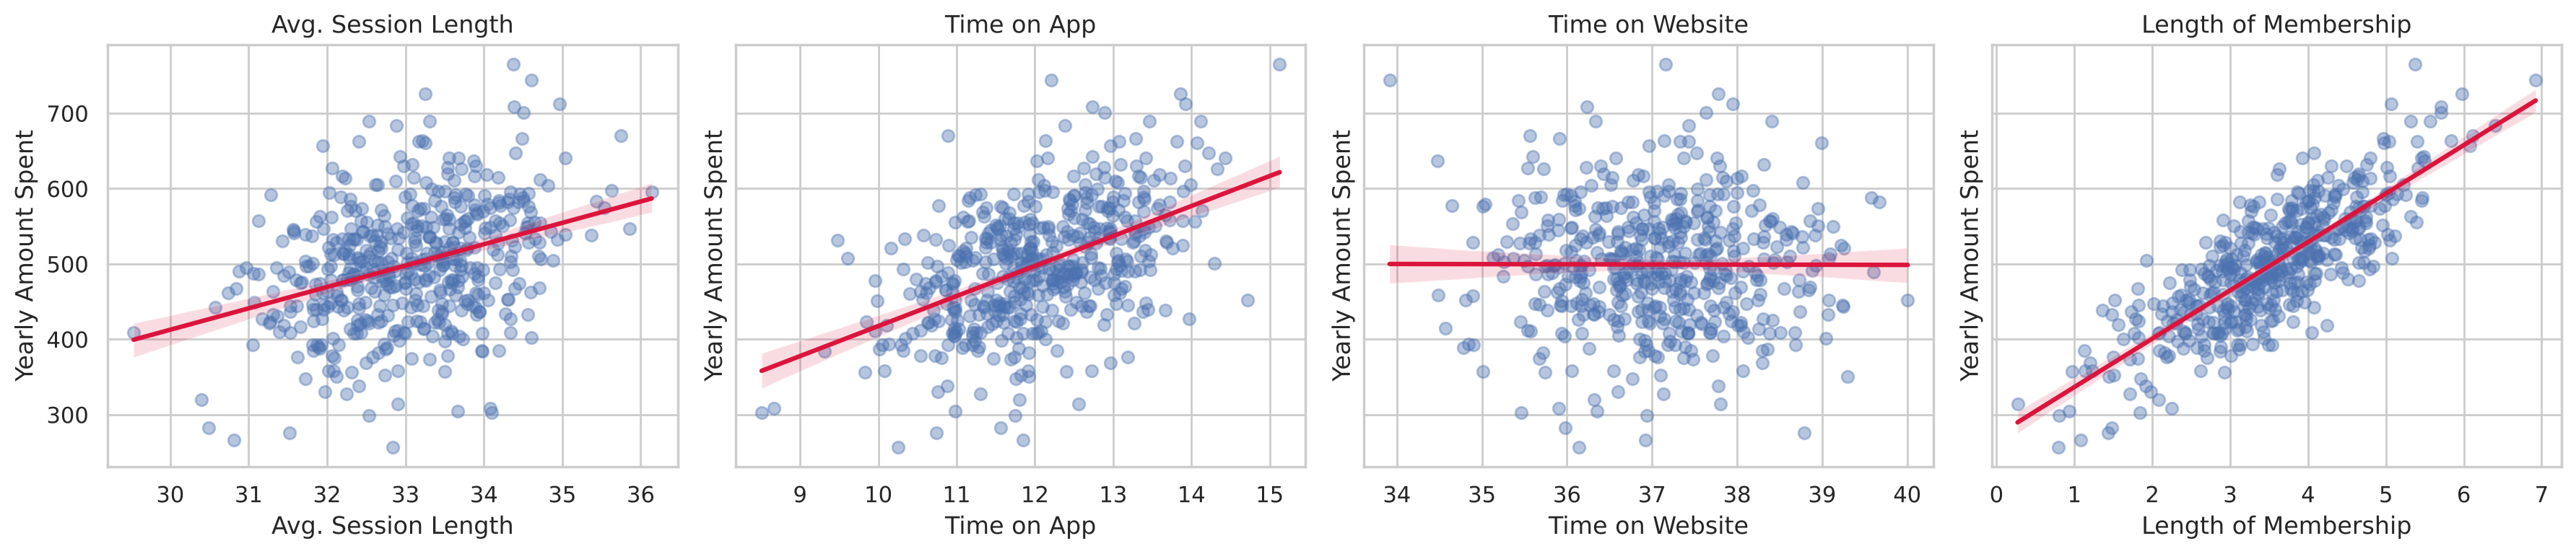

In [3]:
features = ["Avg. Session Length", "Time on App", "Time on Website", "Length of Membership"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, col in zip(axes, features):
    sns.regplot(data=df, x=col, y="Yearly Amount Spent", ax=ax, scatter_kws={"alpha": 0.4}, line_kws={"color": "crimson"})
    ax.set_title(col)
plt.tight_layout(); plt.savefig("images/features_vs_spending.png", dpi=120, bbox_inches="tight"); plt.show()

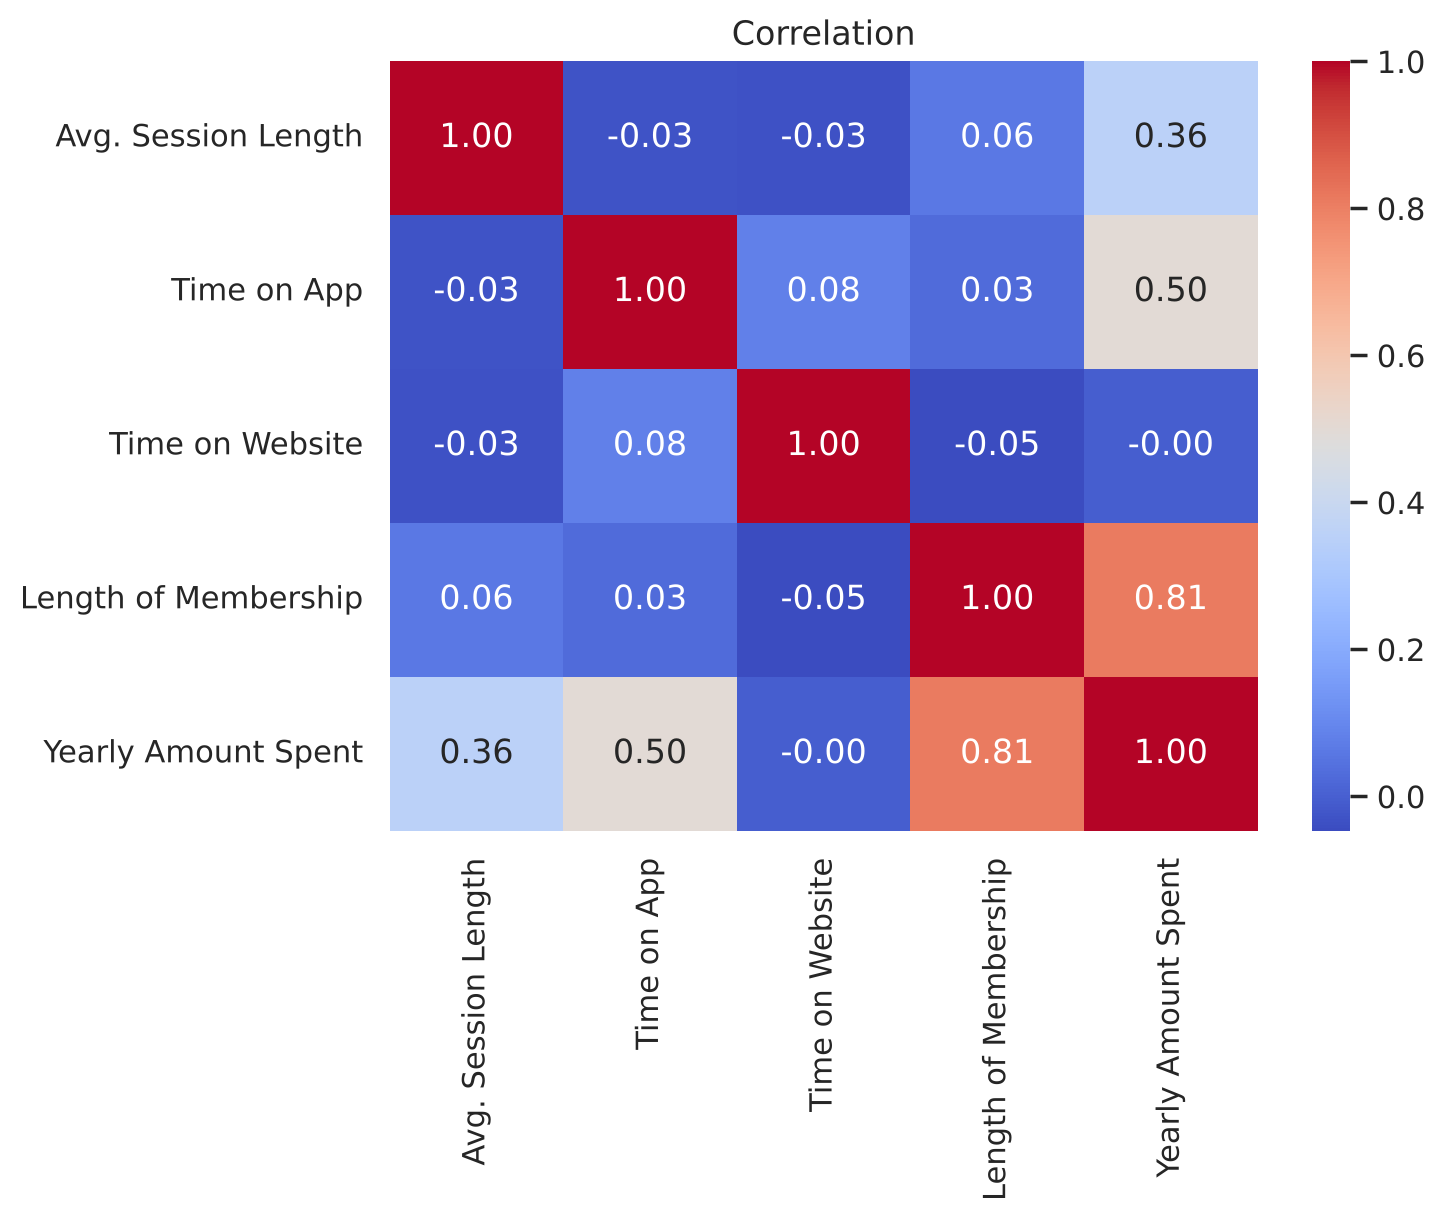

In [4]:
plt.figure(figsize=(7, 5))
sns.heatmap(df[features + ["Yearly Amount Spent"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation"); plt.savefig("images/correlation.png", dpi=120, bbox_inches="tight"); plt.show()

* **Length of Membership** has the strongest relationship with spending, followed by **Time on App**.
* **Time on Website** shows almost no relationship with spending.

## 3. Model

In [5]:
X = df[features]; y = df["Yearly Amount Spent"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

model = Pipeline([
    ("prep", ColumnTransformer([("num", Pipeline([("imputer", SimpleImputer(strategy="mean")), ("scaler", StandardScaler())]), features)])),
    ("model", LinearRegression()),
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(f"R²   : {r2_score(y_test, y_pred):.3f}")
print(f"RMSE : ${root_mean_squared_error(y_test, y_pred):.2f}")
print(f"MAE  : ${mean_absolute_error(y_test, y_pred):.2f}")
cv = cross_val_score(model, X, y, cv=5, scoring="r2")
print(f"5-fold CV R²: {cv.mean():.3f} ± {cv.std():.3f}")

R²   : 0.978
RMSE : $10.48
MAE  : $8.56
5-fold CV R²: 0.984 ± 0.002


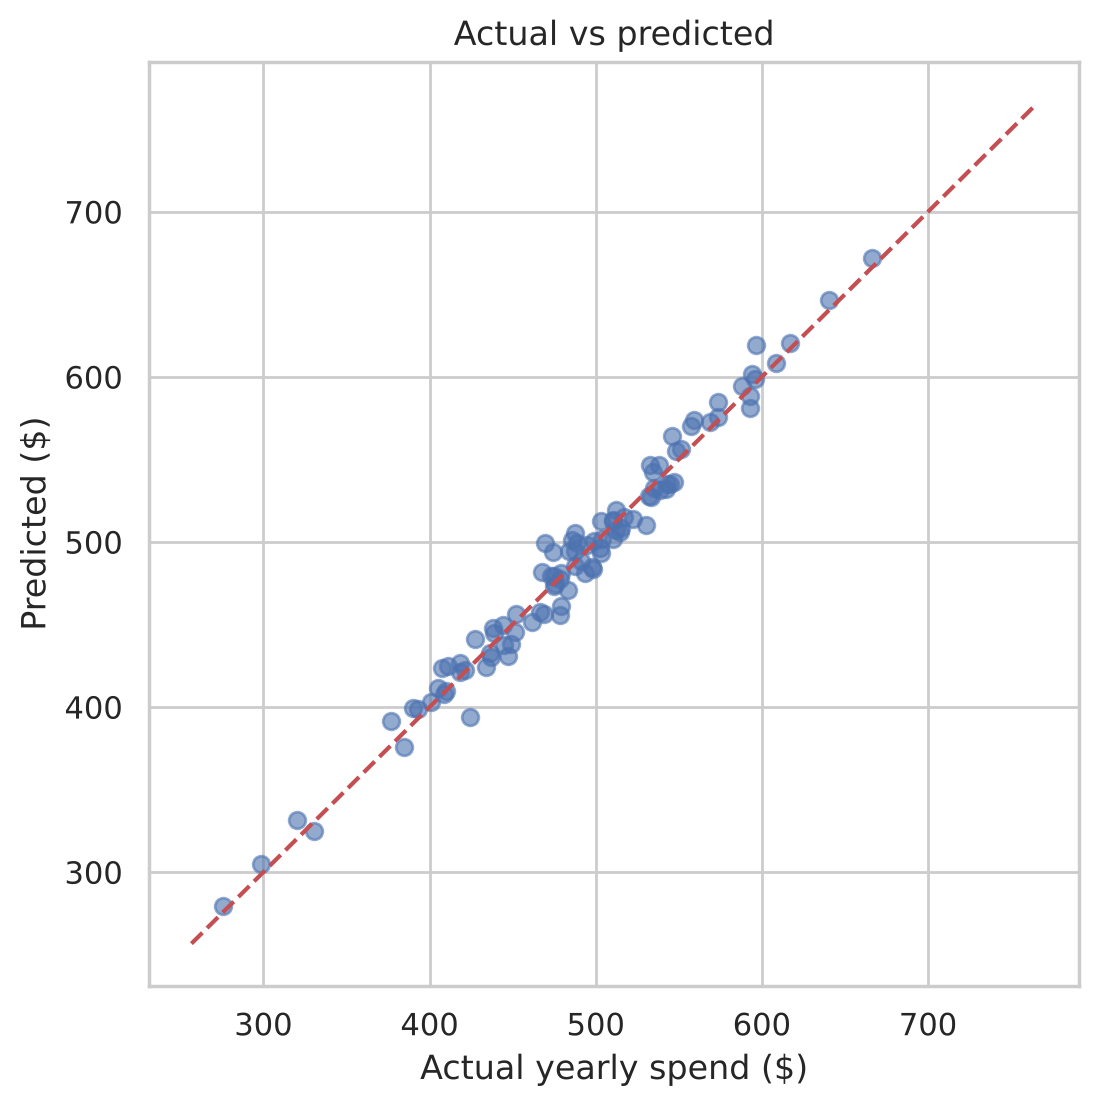

In [6]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
lims = [y.min(), y.max()]; plt.plot(lims, lims, "r--")
plt.xlabel("Actual yearly spend ($)"); plt.ylabel("Predicted ($)"); plt.title("Actual vs predicted")
plt.savefig("images/actual_vs_predicted.png", dpi=120, bbox_inches="tight"); plt.show()

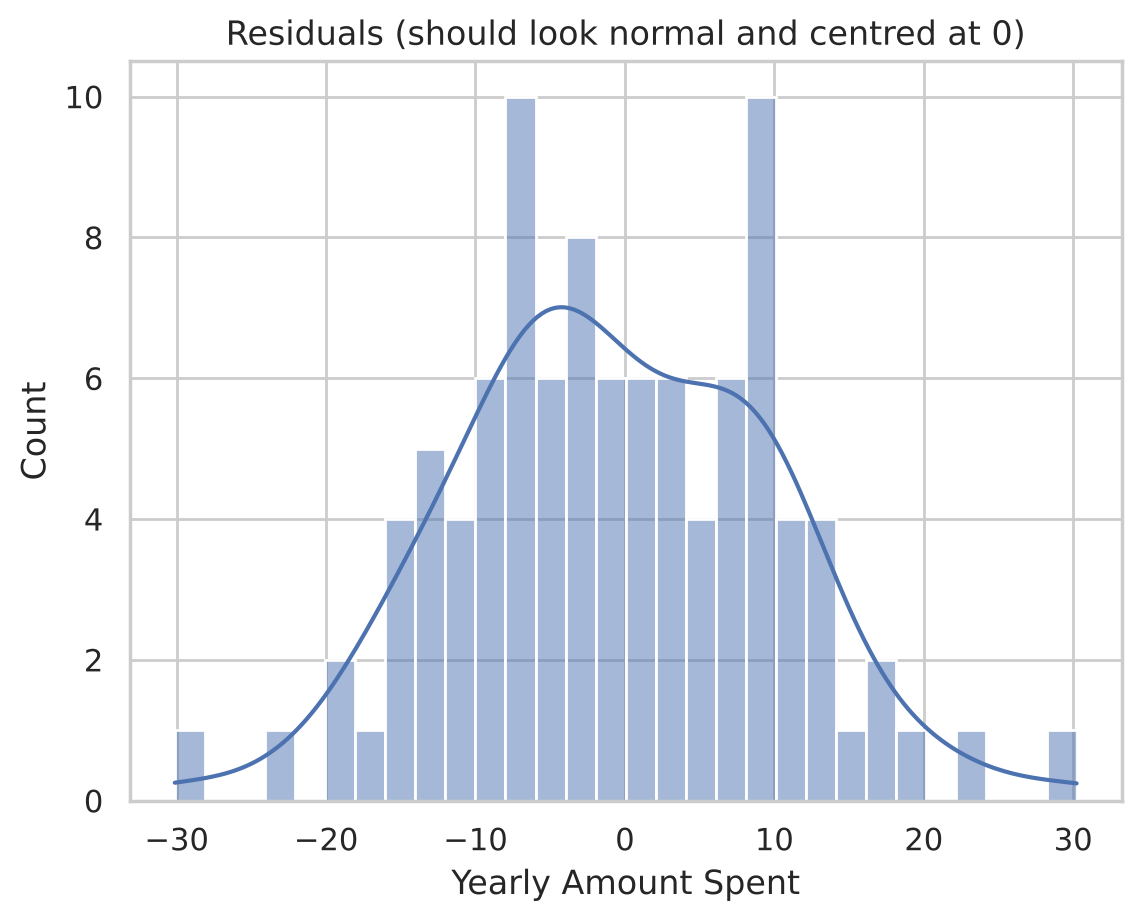

In [7]:
residuals = y_test - y_pred
sns.histplot(residuals, kde=True, bins=30); plt.title("Residuals (should look normal and centred at 0)")
plt.savefig("images/residuals.png", dpi=120, bbox_inches="tight"); plt.show()

## 4. Business answer: interpret the coefficients
To read coefficients in real units ($ per extra minute / year), we fit the same linear model on the **unscaled** features.

In [8]:
raw = LinearRegression().fit(X_train, y_train)
coef = pd.DataFrame({"$ per +1 unit": raw.coef_}, index=features).round(2)
coef

,$ per +1 unit
Avg. Session Length,25.60
Time on App,38.79
Time on Website,0.31
Length of Membership,61.90


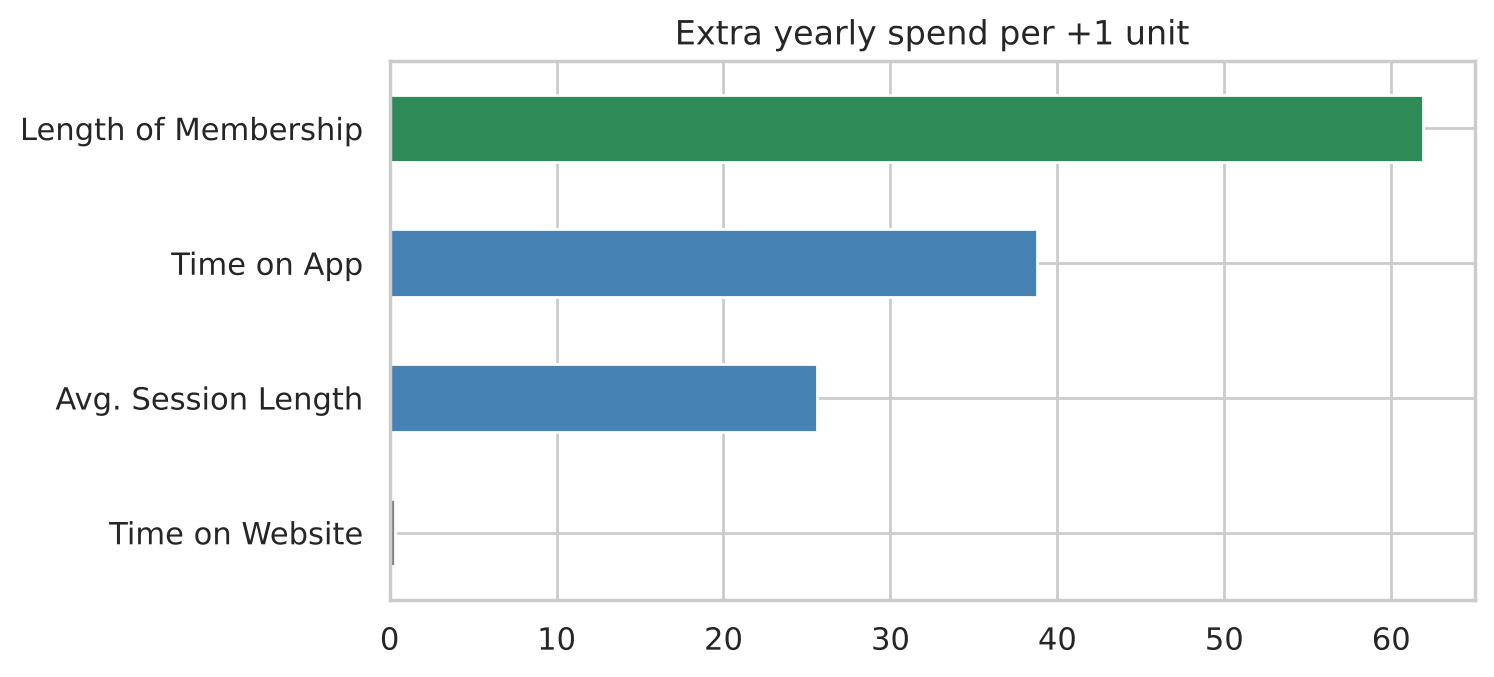

In [9]:
coef["$ per +1 unit"].sort_values().plot(kind="barh", color=["grey", "steelblue", "steelblue", "seagreen"], figsize=(7, 3.5))
plt.title("Extra yearly spend per +1 unit"); plt.savefig("images/coefficients.png", dpi=120, bbox_inches="tight"); plt.show()

## 5. Conclusion

* Holding everything else fixed, **one extra minute on the app ≈ +$39/year**, while **one extra minute on the website ≈ +$0.3/year** — practically nothing.
* **One extra year of membership ≈ +$62/year**, the strongest driver of all.
* **Recommendation:** the app is where the money is. Either double down on the app, or fix the website to make it as effective — but retention (membership length) matters most, so loyalty programmes are worth more than either.
* The model explains ~98% of the variance with a mean absolute error of about $8.6, and residuals are centred at zero, so a linear model is the right tool here.